In [1]:
import gurobipy as gp
from gurobipy import GRB
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd #permite ler e trabalhar com suas planilhas do Excel

#gurobipy: resolve o problema.
#numyy: trabalha com os números.
#matplotlib: mostra os resultados em gráficos.
#import: importa uma biblioteca.
#numpy: é o nome da biblioteca.
#as np: cria um apelido para facilitar a escrita.


In [2]:
#MEUS DADOS

#Usar as coordenadas dos funcionários em excel. "Demanda"

funcionarios = pd.read_excel('COORD_FUNCIONARIOS.xlsx')
funcionarios.head() #Esse comando mostra as primeiras cinco linhas da planilha.

#pd.read_excel() lê uma planilha do Excel.
#'COORDENADAS DE FUNCIONÁRIOS.xlsx' é o nome do arquivo.
#funcionarios é o nome que usamos no Python para guardar os dados importados.


,Nome,X,Y,Quantidade
0,FUNCIONÁRIO 1,-38.698488,-3.734553,1.0
1,FUNCIONÁRIO 2,-38.698456,-3.734330,2.0
2,FUNCIONÁRIO 3,-38.698096,-3.734843,3.0
3,FUNCIONÁRIO 4,-38.698509,-3.734777,4.0
4,FUNCIONÁRIO 5,-38.697810,-3.734874,5.0


In [3]:
#Usar as coordenadas das possiveis paradas. "Localizações de Instalaões'

paradas = pd.read_excel('COORD_PARADAS.xlsx')
paradas.head() #Esse comando mostra as primeiras cinco linhas da planilha.


,Nome,X,Y,Bairro
0,PARADA 1,-38.516663,-3.752989,BAIRRO 11
1,PARADA 2,-38.519194,-3.747714,BAIRRO 11
2,PARADA 3,-38.494691,-3.831588,BAIRRO 12
3,PARADA 4,-38.496704,-3.836253,BAIRRO 12
4,PARADA 5,-38.556713,-3.824176,BAIRRO 13


In [4]:
#DEFINIR OS CONJUNTOS DADOS REAIS:

nos = list(range(len(funcionarios)))
#len conta os funcionários; range(quantidade) gera índices de 0 até quantidade-1; list transforma em lista; nos guarda os índices

localizações = list(range(len(paradas)))
#len conta as paradas; range gera índices de 0 até quantidade-1; list transforma em lista; localizações guarda os índices

arcos = [(i, j) for i in nos for j in localizações]
#Cria todos os pares possíveis entre cada funcionário i e cada parada candidata j

# NÚMERO DE PARADAS A SELECIONAR:

P = 18  # Define quantas paradas o modelo de p-medianas deverá selecionar

# CONFERIR OS CONJUNTOS:

print("Funcionários:", len(nos))  # Mostra a quantidade de pontos de demanda
print("Paradas candidatas:", len(localizações))  # Mostra a quantidade de paradas disponíveis
print("Pares possíveis:", len(arcos))  # Mostra o total de combinações funcionário-parada
print("Paradas a selecionar:", P)  # Mostra a quantidade de paradas que o modelo deverá selecionar

# MATRIZ DE DISTÂNCIAS

distancia = {
    (i, j): np.hypot(
        funcionarios.iloc[i]["X"] - paradas.iloc[j]["X"],
        funcionarios.iloc[i]["Y"] - paradas.iloc[j]["Y"]
    )
    for i in nos
    for j in localizações
}

# Calcula a distância entre cada funcionário i e cada parada candidata j.
# funcionarios.iloc[i]["X"] busca a coordenada X do funcionário i.
# paradas.iloc[j]["X"] busca a coordenada X da parada j.
# A mesma operação é realizada para as coordenadas Y.
# np.hypot calcula a distância em linha reta entre as coordenadas.
# distancia[i,j] armazena a distância calculada para cada combinação.


Funcionários: 86
Paradas candidatas: 36
Pares possíveis: 3096
Paradas a selecionar: 18


In [5]:
# PROBLEMA DE P-MEDIANAS - DADOS REAIS

model = gp.Model("P-Mediana")  # Cria o modelo matemático de otimização

# VARIÁVEIS DE DECISÃO:

x = model.addVars(arcos, vtype=GRB.BINARY, name="x")

# Cria as variáveis de decisão x[i,j] e guarda essas variáveis em x.
# model.addVars(arcos) cria uma variável para cada combinação de funcionário i e parada candidata j.
# vtype=GRB.BINARY define que cada variável só pode assumir os valores 0 ou 1.
# name="x" define o nome das variáveis dentro do modelo do Gurobi.
# x[i,j] = 1 se o funcionário i for associado à parada j.
# x[i,j] = 0 caso contrário.

y = model.addVars(localizações, vtype=GRB.BINARY, name="y")

# Cria as variáveis de decisão y[j] e guarda essas variáveis em y.
# model.addVars(localizações) cria uma variável para cada parada candidata.
# vtype=GRB.BINARY define que cada variável só pode assumir os valores 0 ou 1.
# name="y" define o nome das variáveis dentro do modelo do Gurobi.
# y[j] = 1 se a parada candidata j for selecionada.
# y[j] = 0 se a parada candidata j não for selecionada.

# FUNÇÃO OBJETIVO

model.setObjective(gp.quicksum(distancia[i,j]*x[i,j] for i,j in arcos)),GRB.MINIMIZE

# Multiplica a distância entre cada funcionário i e cada parada j
# pela variável x[i,j], que indica se o funcionário será associado à parada.
# quicksum soma os resultados de todas as combinações de funcionários e paradas.
# GRB.MINIMIZE define que o objetivo é minimizar a soma das distâncias.

# RESTRIÇÕES

model.addConstrs((gp.quicksum(x[i,j] for j in localizações) == 1 for i in nos), name="Associacao")
# Garante que cada funcionário i seja associado a exatamente uma parada candidata j.
# quicksum soma as variáveis x[i,j] de todas as paradas candidatas.
# == 1 determina que a soma deve ser igual a 1 para cada funcionário.
# for i in nos repete essa condição para todos os funcionários

model.addConstr(gp.quicksum(y[j] for j in localizações) == P, name="Numero_Paradas")
# Define o número de paradas que serão selecionadas.
# quicksum soma as variáveis y[j] de todas as paradas candidatas.
# y[j] = 1 indica que a parada j foi selecionada.
# y[j] = 0 indica que a parada j não foi selecionada.
# == P exige que sejam selecionadas exatamente P paradas.

model.addConstrs((x[i,j] <= y[j] for i,j in arcos),name="Vinculo")

# Garante que um funcionário só seja associado a uma parada selecionada.
# x[i,j] representa a associação do funcionário i à parada j.
# y[j] indica se a parada j foi selecionada.
# Se y[j] = 0, x[i,j] também deverá ser 0.
# Se x[i,j] = 1, obrigatoriamente y[j] deverá ser 1.
# A restrição é aplicada a todas as combinações de funcionários e paradas.

model.update()

Set parameter Username
Set parameter LicenseID to value 2782139
Academic license - for non-commercial use only - expires 2027-02-23


In [6]:
# EXECUÇÃO DO MODELO

# Executa o Gurobi para buscar a solução ótima do problema de p-medianas.
model.optimize()

# Mostra o status da otimização.
print("Status do modelo:", model.Status)

# Mostra a quantidade de soluções encontradas pelo Gurobi.
print("Soluções encontradas:", model.SolCount)

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 3183 rows, 3132 columns and 9324 nonzeros (Min)
Model fingerprint: 0x0c327bf5
Model has 3096 linear objective coefficients
Variable types: 0 continuous, 3132 integer (3132 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-04, 5e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]

Presolve time: 0.02s
Presolved: 3183 rows, 3132 columns, 9324 nonzeros
Variable types: 0 continuous, 3132 integer (3132 binary)
Found heuristic solution: objective 6.3310576

Root relaxation: objective 2.970083e-01, 197 iterations, 0.00 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent  

In [7]:
# ARCOS ATIVOS

# Percorre todos os arcos possíveis entre funcionários e paradas.
# x[i,j].X retorna o valor da variável de decisão na solução encontrada.
# Como x[i,j] é binária, seu valor será 0 ou 1.
# Se x[i,j] == 1, a associação foi selecionada.
arcos_ativos = [(i, j) for i, j in arcos if x[i, j].X > 0.5]

# Mostra os arcos ativos encontrados.
print("Arcos ativos:", arcos_ativos)

Arcos ativos: [(0, 15), (1, 15), (2, 15), (3, 15), (4, 15), (5, 15), (6, 15), (7, 15), (8, 15), (9, 15), (10, 30), (11, 30), (12, 30), (13, 30), (14, 22), (15, 22), (16, 22), (17, 22), (18, 22), (19, 16), (20, 16), (21, 16), (22, 16), (23, 16), (24, 21), (25, 21), (26, 21), (27, 21), (28, 21), (29, 35), (30, 35), (31, 35), (32, 35), (33, 18), (34, 18), (35, 18), (36, 18), (37, 13), (38, 13), (39, 13), (40, 13), (41, 32), (42, 32), (43, 32), (44, 32), (45, 0), (46, 0), (47, 0), (48, 0), (49, 0), (50, 0), (51, 10), (52, 10), (53, 10), (54, 10), (55, 3), (56, 3), (57, 3), (58, 3), (59, 3), (60, 3), (61, 27), (62, 27), (63, 27), (64, 28), (65, 28), (66, 28), (67, 5), (68, 5), (69, 5), (70, 5), (71, 5), (72, 6), (73, 6), (74, 6), (75, 6), (76, 6), (77, 8), (78, 8), (79, 8), (80, 25), (81, 25), (82, 25), (83, 25), (84, 15), (85, 30)]


In [8]:
# LOCALIZAÇÕES ATIVAS

# Percorre todas as localizações candidatas.
# y[j].X retorna o valor da variável de decisão da localização j.
# Se y[j].X > 0.5, significa que a parada foi selecionada.
localizações_ativas = [j for j in localizações if y[j].X > 0.5]

# Mostra as localizações selecionadas pelo modelo.
print("Localizações ativas:", localizações_ativas)

Localizações ativas: [0, 3, 5, 6, 8, 10, 13, 15, 16, 18, 21, 22, 25, 27, 28, 30, 32, 35]


In [9]:
# MOSTRA OS DADOS DAS PARADAS SELECIONADAS

# Seleciona, na planilha paradas, as linhas correspondentes às localizações ativas.
paradas_selecionadas = paradas.iloc[localizações_ativas]

# Mostra as informações das paradas selecionadas.
print(paradas_selecionadas)

         Nome          X         Y     Bairro
0    PARADA 1 -38.516663 -3.752989  BAIRRO 11
3    PARADA 4 -38.496704 -3.836253  BAIRRO 12
5    PARADA 6 -38.556623 -3.828528  BAIRRO 13
6    PARADA 7 -38.577029 -3.819706  BAIRRO 14
8    PARADA 9 -38.579009 -3.865035  BAIRRO 15
10  PARADA 11 -38.593088 -3.740918  BAIRRO 10
13  PARADA 14 -38.655550 -3.723490   BAIRRO 9
15  PARADA 16 -38.698064 -3.733392   BAIRRO 1
16  PARADA 17 -38.747999 -3.706370   BAIRRO 3
18  PARADA 19 -38.700874 -3.701406   BAIRRO 8
21  PARADA 22 -38.707984 -3.692441   BAIRRO 5
22  PARADA 23 -38.824656 -3.711433   BAIRRO 4
25  PARADA 26 -38.966728 -3.607014  BAIRRO 18
27  PARADA 28 -38.900723 -3.587636  BAIRRO 16
28  PARADA 29 -38.831392 -3.556315  BAIRRO 17
30  PARADA 31 -38.825758 -3.589680   BAIRRO 2
32  PARADA 33 -38.748981 -3.656026   BAIRRO 6
35  PARADA 36 -38.912000 -3.685522   BAIRRO 7


In [10]:

# Importa as funções matemáticas necessárias
from math import radians, sin, cos, sqrt, atan2

# Define a função para calcular a distância geográfica em metros
def distancia_metros(lat1, lon1, lat2, lon2):

    # Converte as coordenadas de graus para radianos
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    # Calcula a diferença entre as latitudes e longitudes
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Aplica a fórmula de Haversine
    a = (sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2)

    # Retorna a distância em metros
    return 6371000 * 2 * atan2(
        sqrt(a), sqrt(1 - a))


# Verifica se o Gurobi encontrou uma solução
if model.SolCount > 0:

    # Extrai os arcos selecionados pelo Gurobi
    arcos_ativos = [
        (i, j)
        for i, j in x.keys()
        if x[i, j].X > 0.5
    ]

    # Percorre os arcos ativos
    for i, j in arcos_ativos:

        # Obtém as coordenadas do funcionário
        lat_func = funcionarios.iloc[i]["X"]
        lon_func = funcionarios.iloc[i]["Y"]

        # Obtém as coordenadas da parada
        lat_parada = paradas.iloc[j]["X"]
        lon_parada = paradas.iloc[j]["Y"]

        # Calcula a distância em metros
        d_metros = distancia_metros(lat_func, lon_func, lat_parada, lon_parada)

        # Exibe o resultado
        print(f"Funcionário {i + 1} → Parada {j + 1}: " f"{d_metros:.2f} metros" )



Funcionário 1 → Parada 16: 111.25 metros
Funcionário 2 → Parada 16: 92.31 metros
Funcionário 3 → Parada 16: 125.90 metros
Funcionário 4 → Parada 16: 129.92 metros
Funcionário 5 → Parada 16: 131.65 metros
Funcionário 6 → Parada 16: 157.15 metros
Funcionário 7 → Parada 16: 218.70 metros
Funcionário 8 → Parada 16: 214.47 metros
Funcionário 9 → Parada 16: 197.13 metros
Funcionário 10 → Parada 16: 64.40 metros
Funcionário 11 → Parada 31: 42.23 metros
Funcionário 12 → Parada 31: 106.83 metros
Funcionário 13 → Parada 31: 161.96 metros
Funcionário 14 → Parada 31: 43.44 metros
Funcionário 15 → Parada 23: 87.58 metros
Funcionário 16 → Parada 23: 126.47 metros
Funcionário 17 → Parada 23: 109.23 metros
Funcionário 18 → Parada 23: 152.06 metros
Funcionário 19 → Parada 23: 165.11 metros
Funcionário 20 → Parada 17: 175.47 metros
Funcionário 21 → Parada 17: 150.70 metros
Funcionário 22 → Parada 17: 93.10 metros
Funcionário 23 → Parada 17: 14.17 metros
Funcionário 24 → Parada 17: 95.39 metros
Funcionár

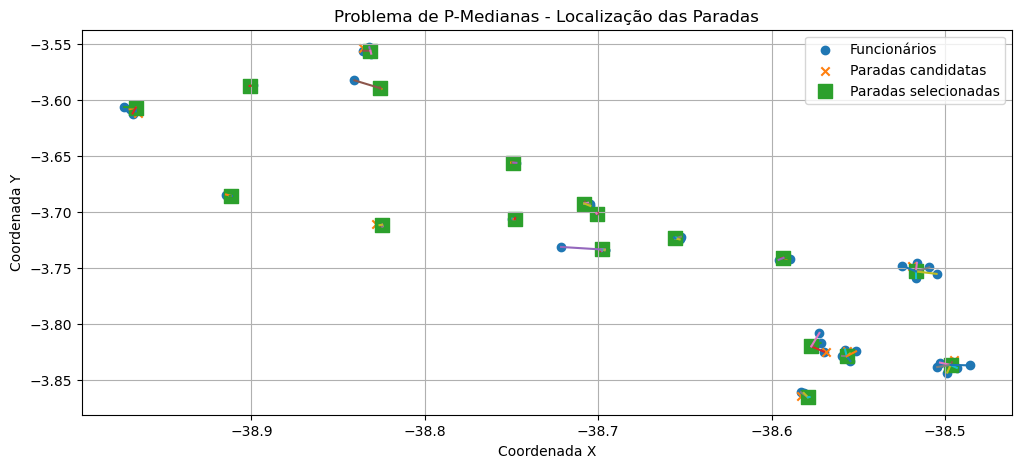

In [11]:
# GRÁFICO DO PROBLEMA DE P-MEDIANAS

import matplotlib.pyplot as plt  # Importa a biblioteca para criar gráficos.

plt.figure(figsize=(12, 5))  # Define o tamanho da figura.

# Plota os funcionários usando suas coordenadas.
plt.scatter(
    funcionarios["X"], funcionarios["Y"],
    label="Funcionários", marker="o"
)

# Plota todas as paradas candidatas.
plt.scatter(
    paradas["X"], paradas["Y"],
    label="Paradas candidatas", marker="x"
)

# Destaca as 18 paradas selecionadas pelo modelo.
plt.scatter(
    paradas.iloc[localizações_ativas]["X"],
    paradas.iloc[localizações_ativas]["Y"],
    label="Paradas selecionadas", marker="s", s=100
)

# Desenha as associações entre os funcionários e as paradas selecionadas.
for i, j in arcos_ativos:
    plt.plot(
        [funcionarios.iloc[i]["X"], paradas.iloc[j]["X"]],
        [funcionarios.iloc[i]["Y"], paradas.iloc[j]["Y"]]
    )

# Adiciona título e identificação dos eixos.
plt.title("Problema de P-Medianas - Localização das Paradas")
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")

# Exibe a legenda e a grade.
plt.legend()
plt.grid(True)

# Mostra o gráfico.
plt.show()